# Bank Marketing — Statistics CA1
**Student:** Ariunbolor Chimed-Ochir | **ID:** 2026682

**GitHub repository:** [INSERT YOUR ACTUAL GITHUB REPOSITORY LINK HERE]

Place `bank-full.csv` beside this notebook, then select **Kernel → Restart & Run All**. This notebook was assembled from prior analysis; run it to generate reproducible outputs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson, norm, skew
df = pd.read_csv("bank-full.csv", sep=";")
print("Shape:", df.shape)
display(df.head())
print(df.isna().sum())

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


## 1. Descriptive statistics and three plots
Histograms display numerical shapes; the count plot compares binary categories. The `unknown` category and `pdays=-1` are sentinel codes rather than conventional NaN values.

,age,balance,duration,campaign,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,258.163080,2.763841,0.580323
std,10.618762,3044.765829,257.527812,3.098021,2.303441
min,18.000000,-8019.000000,0.000000,1.000000,0.000000
25%,33.000000,72.000000,103.000000,1.000000,0.000000
50%,39.000000,448.000000,180.000000,2.000000,0.000000
75%,48.000000,1428.000000,319.000000,3.000000,0.000000
max,95.000000,102127.000000,4918.000000,63.000000,275.000000


y
no     39922
yes     5289
Name: count, dtype: int64


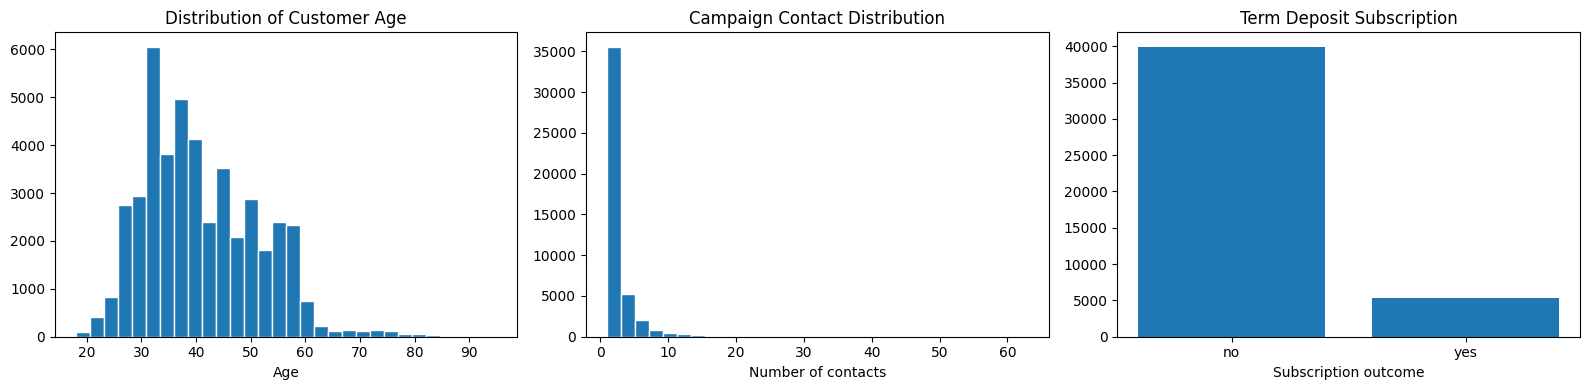

In [2]:
display(df[["age", "balance", "duration", "campaign", "previous"]].describe())
print(df["y"].value_counts())
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df["age"], bins=30, edgecolor="white")
axes[0].set_title("Distribution of Customer Age")
axes[0].set_xlabel("Age")
axes[1].hist(df["campaign"], bins=30, edgecolor="white")
axes[1].set_title("Campaign Contact Distribution")
axes[1].set_xlabel("Number of contacts")
counts = df["y"].value_counts().reindex(["no", "yes"])
axes[2].bar(counts.index, counts.values)
axes[2].set_title("Term Deposit Subscription")
axes[2].set_xlabel("Subscription outcome")
plt.tight_layout()
plt.show()

## 2. Binomial model
For a hypothetical 20 independent customers with constant subscription probability p, X~Binomial(20,p). E(X)=np and Var(X)=np(1-p). With larger n, the success proportion X/n becomes more concentrated around p; the Normal approximation requires sufficiently large np and n(1-p).

Successes: 5289 p: 0.117
Expected: 2.34 Variance: 2.07
P(X=3): 0.2202


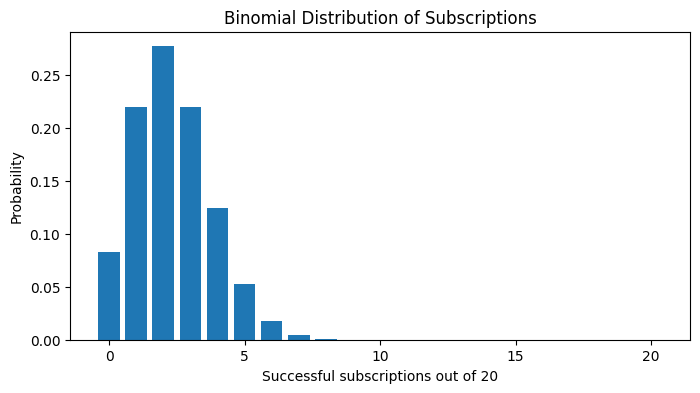

In [3]:
p = (df["y"] == "yes").mean()
n = 20
x = np.arange(n+1)
print("Successes:", (df["y"] == "yes").sum(), "p:", round(p,4))
print("Expected:", round(n*p,2), "Variance:", round(n*p*(1-p),2))
print("P(X=3):", round(binom.pmf(3,n,p),4))
plt.figure(figsize=(8,4))
plt.bar(x, binom.pmf(x,n,p))
plt.title("Binomial Distribution of Subscriptions")
plt.xlabel("Successful subscriptions out of 20")
plt.ylabel("Probability")
plt.show()

## 3. Poisson model
A Poisson distribution assumes mean = variance and permits zero counts. The campaign variable starts at one, and its empirical variance exceeds its mean; this model is illustrative rather than a good fit.

Mean: 2.764 Variance: 9.598 Variance/Mean: 3.473
Poisson P(X=3): 0.2219


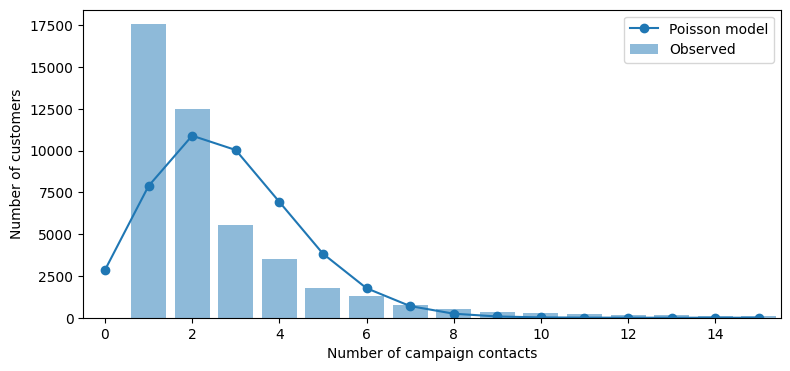

In [4]:
lam = df["campaign"].mean()
var = df["campaign"].var()
print("Mean:",round(lam,3),"Variance:",round(var,3),"Variance/Mean:",round(var/lam,3))
print("Poisson P(X=3):",round(poisson.pmf(3,lam),4))
obs = df["campaign"].value_counts().sort_index()
x = np.arange(0,16)
plt.figure(figsize=(9,4))
plt.bar(obs.index,obs.values,alpha=.5,label="Observed")
plt.plot(x,poisson.pmf(x,lam)*len(df),marker="o",label="Poisson model")
plt.xlim(-.5,15.5)
plt.xlabel("Number of campaign contacts")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

## 4. Normal model
Age is integer-valued and right-skewed; the Normal curve is an approximation, not a claim of exact normality.

Mean: 40.936 SD: 10.619 Skew: 0.685


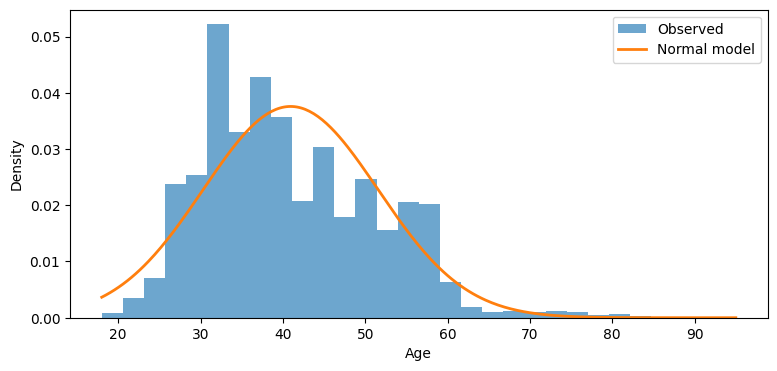

Normal P(30<=Age<=50): 0.6518
Observed proportion ages 30–50 inclusive: 0.6787


In [5]:
mu = df["age"].mean()
sigma = df["age"].std()
print("Mean:",round(mu,3),"SD:",round(sigma,3),"Skew:",round(skew(df["age"]),3))
xs = np.linspace(df["age"].min(),df["age"].max(),300)
plt.figure(figsize=(9,4))
plt.hist(df["age"],bins=30,density=True,alpha=.65,label="Observed")
plt.plot(xs,norm.pdf(xs,mu,sigma),linewidth=2,label="Normal model")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()
print("Normal P(30<=Age<=50):",round(norm.cdf(50,mu,sigma)-norm.cdf(30,mu,sigma),4))
print("Observed proportion ages 30–50 inclusive:",round(df["age"].between(30,50).mean(),4))

## 5. Larger sample demonstration
This simulation varies the number of hypothetical independent Binomial trials and shows how the sample proportion approaches p. It is a model demonstration, not additional observed banking data.

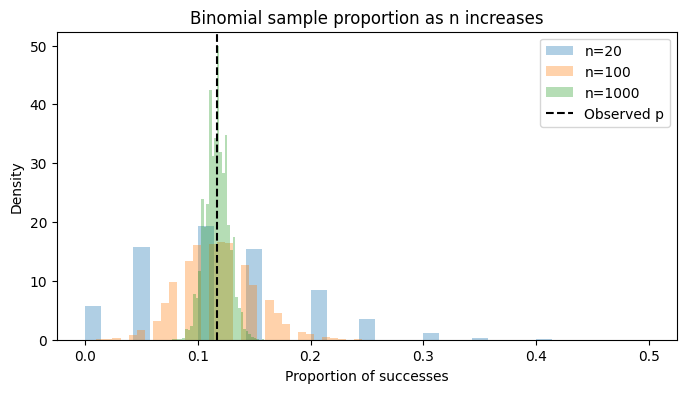

In [6]:
rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(8, 4))
for size in [20, 100, 1000]:
    proportions = rng.binomial(size, p, 10000) / size
    ax.hist(proportions, bins=35, density=True, alpha=0.35, label=f"n={size}")
ax.axvline(p, color="black", linestyle="--", label="Observed p")
ax.set_xlabel("Proportion of successes")
ax.set_ylabel("Density")
ax.set_title("Binomial sample proportion as n increases")
ax.legend()
plt.show()